# Chapter 21: Dropout, noise and other regularisers

Checks [chapter 21](../../book/21-dropout-and-noise.md). The model is **linear in its weights**, with squared error: a
sum of features times weights. Features are random numbers, or sine and cosine terms of fixed integer frequency (linear
in the weights, so no amplitudes and phases are trained). Dropout expectations are computed **exactly** by listing every
mask with its probability, not by sampling, except where a cell says it samples. Everything is NumPy in float64, seeded.
These are measurements, not proofs: the proofs are in `Dropout.lean` and `Regularisers.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import itertools
import numpy as np
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE, DATA

use_style()
SEED = 21


def make_mask_table(keep_probability, feature_count):
    """Every dropout mask with its probability. A kept feature is scaled by 1 / keep_probability."""
    kept = np.array(list(itertools.product([0, 1], repeat=feature_count)), dtype=float)
    chances = np.prod(np.where(kept == 1, keep_probability, 1 - keep_probability), axis=1)
    return kept / keep_probability, chances


def get_mask_variance(keep_probability):
    return (1 - keep_probability) / keep_probability


def get_expected_dropout_loss(masks, chances, label, shares):
    noisy_answers = masks @ shares
    return float(chances @ (label - noisy_answers) ** 2)

## Claim 1: the two worked examples

Predicted: the mean squared error of the four masks of the chapter's example is 10, with penalty `1 x (3^2 + 1^2) = 10`;
at keep probability `9 / 10` it is `10 / 9`. The input-noise example (line `2 x input`, input 1, label 2, noise
`+0.5` or `-0.5`) gives 1. A different number would count against the table in the chapter.

In [2]:
masks, chances = make_mask_table(0.5, 2)
half_loss = get_expected_dropout_loss(masks, chances, 4.0, np.array([3.0, 1.0]))
report("keep 1/2, shares 3 and 1, label 4: expected squared error is 10", abs(half_loss - 10.0) < 1e-12, f"measured {half_loss:.6f}")
print("the four masks and their squared errors:", [(tuple(float(entry) for entry in mask), round(float((4 - mask @ np.array([3.0, 1.0])) ** 2), 6)) for mask in masks])
masks, chances = make_mask_table(0.9, 2)
ninth_loss = get_expected_dropout_loss(masks, chances, 4.0, np.array([3.0, 1.0]))
report("keep 9/10: expected squared error is 10 / 9", abs(ninth_loss - 10 / 9) < 1e-12, f"measured {ninth_loss:.6f}, mask variance {get_mask_variance(0.9):.6f}")
noises = np.array([0.5, -0.5])
noisy_error = float(np.mean((2.0 - 2.0 * (1.0 + noises)) ** 2))
report("input noise of +-0.5 on the line 2 x input: mean squared error is 1", abs(noisy_error - 1.0) < 1e-12, f"measured {noisy_error:.6f}")

[PASS] keep 1/2, shares 3 and 1, label 4: expected squared error is 10  (measured 10.000000)
the four masks and their squared errors: [((0.0, 0.0), 16.0), ((0.0, 2.0), 4.0), ((2.0, 0.0), 4.0), ((2.0, 2.0), 16.0)]
[PASS] keep 9/10: expected squared error is 10 / 9  (measured 1.111111, mask variance 0.111111)
[PASS] input noise of +-0.5 on the line 2 x input: mean squared error is 1  (measured 1.000000)


True

## Claim 2: dropout adds a penalty (`expected_dropout_loss`)

Eight features, five keep probabilities (0.9, 0.75, 0.5, 0.25, 0.1), 20 random examples each (random shares and label).
All 256 masks are listed, so the expectation is exact. Predicted: the expected squared error equals
`plain_loss + mask_variance x sum of squared shares` up to rounding (below `1e-9` relative). Two controls break a hypothesis.
**Correlated masks**: all features share one mask, so the variances do not add. The formula should fail, and the right
penalty becomes `mask_variance x (sum of shares)^2`. **Masks not scaled up**: kept features are not divided by the keep
probability, so the masks are not one on average. The formula should fail. Each control must be off by more than `1e-3`
relative somewhere, or the check would not be able to fail.

In [3]:
generator = np.random.default_rng(SEED)
FEATURE_COUNT = 8
worst_relative_gap = 0.0
worst_variance_gap = 0.0
correlated_relative_gap = 0.0
correlated_fix_gap = 0.0
unscaled_relative_gap = 0.0
for keep_probability in (0.9, 0.75, 0.5, 0.25, 0.1):
    masks, chances = make_mask_table(keep_probability, FEATURE_COUNT)
    mask_variance = get_mask_variance(keep_probability)
    worst_variance_gap = max(worst_variance_gap, abs(float(chances @ (masks[:, 0] - 1) ** 2) - mask_variance))
    unscaled_masks = masks * keep_probability
    for example in range(20):
        shares = generator.standard_normal(FEATURE_COUNT) * 1.5
        label = generator.standard_normal() * 3
        plain_loss = (label - shares.sum()) ** 2
        penalty = mask_variance * (shares ** 2).sum()
        exact = get_expected_dropout_loss(masks, chances, label, shares)
        worst_relative_gap = max(worst_relative_gap, abs(exact - plain_loss - penalty) / exact)
        shared = masks[:, [0]] * np.ones((1, FEATURE_COUNT))       # one mask for every feature
        correlated = get_expected_dropout_loss(shared, chances, label, shares)
        correlated_relative_gap = max(correlated_relative_gap, abs(correlated - plain_loss - penalty) / correlated)
        correlated_fix_gap = max(correlated_fix_gap, abs(correlated - plain_loss - mask_variance * shares.sum() ** 2) / correlated)
        unscaled = get_expected_dropout_loss(unscaled_masks, chances, label, shares)
        unscaled_relative_gap = max(unscaled_relative_gap, abs(unscaled - plain_loss - penalty) / unscaled)
report("the mask variance listed from the table equals (1 - keep) / keep, five keep probabilities", worst_variance_gap < 1e-12, f"largest gap {worst_variance_gap:.1e}")
report("expected squared error = plain error + mask_variance x sum of squared shares, 100 cases", worst_relative_gap < 1e-9, f"largest relative gap {worst_relative_gap:.1e}")
report("control: with one shared mask the formula fails", correlated_relative_gap > 1e-3, f"largest relative gap {correlated_relative_gap:.2f}")
report("control: the shared-mask loss is plain + mask_variance x (sum of shares)^2 instead", correlated_fix_gap < 1e-9, f"largest relative gap {correlated_fix_gap:.1e}")
report("control: masks that are not one on average break the formula", unscaled_relative_gap > 1e-3, f"largest relative gap {unscaled_relative_gap:.2f}")

[PASS] the mask variance listed from the table equals (1 - keep) / keep, five keep probabilities  (largest gap 3.6e-15)
[PASS] expected squared error = plain error + mask_variance x sum of squared shares, 100 cases  (largest relative gap 1.0e-15)
[PASS] control: with one shared mask the formula fails  (largest relative gap 830.46)
[PASS] control: the shared-mask loss is plain + mask_variance x (sum of shares)^2 instead  (largest relative gap 2.3e-15)
[PASS] control: masks that are not one on average break the formula  (largest relative gap 100.45)


True

## Claim 3: over a data set it is weight decay (`expected_dropout_loss_dataset`, `expected_dropout_loss_of_equal_features`)

Twelve examples, six features, keep probability 0.8 (mask variance 0.25), labels random. The columns of the feature matrix
are scaled so that every feature has the same total squared size `feature_size = 3`. Predicted: for random weights, the exact
dropout loss summed over the examples equals the plain loss plus `mask_variance x feature_size x (squared length of the weights)`, which is weight decay with
`decay_strength = mask_variance x feature_size = 0.75`. Predicted next: the weights that minimise the dropout loss are the weight-decay
(ridge) solution `(features^T features + decay_strength x identity)^-1 features^T labels`. Checked by looking for any random nudge
of size `1e-2` that lowers the exact dropout loss: none should.
The control breaks "equal sizes": columns of sizes 1 to 6. Then weight decay with the average strength should no longer be the
minimiser, and the exact minimiser has a separate decay per feature (the penalty `mask_variance x size_j x weight_j^2` of `expected_dropout_loss_dataset`). The excess loss of the one-strength ridge solution is reported.

In [4]:
generator = np.random.default_rng(SEED + 1)
EXAMPLE_COUNT, DATA_FEATURES, KEEP = 12, 6, 0.8
mask_variance = get_mask_variance(KEEP)
masks, chances = make_mask_table(KEEP, DATA_FEATURES)
labels = generator.standard_normal(EXAMPLE_COUNT) * 2


def get_dataset_dropout_loss(features, labels, weights):
    noisy_answers = masks @ (features * weights).T            # one row per mask, one column per example
    return float(((labels[None, :] - noisy_answers) ** 2 * chances[:, None]).sum())


def get_plain_loss(features, labels, weights):
    return float(((labels - features @ weights) ** 2).sum())


def scale_columns(features, sizes):
    return features * np.sqrt(sizes) / np.linalg.norm(features, axis=0)


FEATURE_SIZE = 3.0
equal_features = scale_columns(generator.standard_normal((EXAMPLE_COUNT, DATA_FEATURES)), np.full(DATA_FEATURES, FEATURE_SIZE))
worst_gap = 0.0
for trial in range(50):
    weights = generator.standard_normal(DATA_FEATURES)
    exact = get_dataset_dropout_loss(equal_features, labels, weights)
    formula = get_plain_loss(equal_features, labels, weights) + mask_variance * FEATURE_SIZE * (weights ** 2).sum()
    worst_gap = max(worst_gap, abs(exact - formula) / exact)
report("equal features: dropout loss = plain loss + mask_variance x feature_size x squared length, 50 weight vectors", worst_gap < 1e-9, f"largest relative gap {worst_gap:.1e}")

DECAY = mask_variance * FEATURE_SIZE
ridge_weights = np.linalg.solve(equal_features.T @ equal_features + DECAY * np.eye(DATA_FEATURES), equal_features.T @ labels)
ridge_loss = get_dataset_dropout_loss(equal_features, labels, ridge_weights)
smallest_rise = min(get_dataset_dropout_loss(equal_features, labels, ridge_weights + 1e-2 * generator.standard_normal(DATA_FEATURES)) - ridge_loss for trial in range(2000))
report("equal features: no random nudge lowers the exact dropout loss at the ridge solution, 2000 nudges", smallest_rise > 0, f"smallest rise {smallest_rise:.2e}")

uneven_sizes = np.arange(1.0, 7.0)
uneven_features = scale_columns(generator.standard_normal((EXAMPLE_COUNT, DATA_FEATURES)), uneven_sizes)
one_strength = mask_variance * uneven_sizes.mean()
one_strength_weights = np.linalg.solve(uneven_features.T @ uneven_features + one_strength * np.eye(DATA_FEATURES), uneven_features.T @ labels)
per_feature_weights = np.linalg.solve(uneven_features.T @ uneven_features + np.diag(mask_variance * uneven_sizes), uneven_features.T @ labels)
one_strength_loss = get_dataset_dropout_loss(uneven_features, labels, one_strength_weights)
per_feature_loss = get_dataset_dropout_loss(uneven_features, labels, per_feature_weights)
smallest_rise = min(get_dataset_dropout_loss(uneven_features, labels, per_feature_weights + 1e-2 * generator.standard_normal(DATA_FEATURES)) - per_feature_loss for trial in range(2000))
report("uneven features: the per-feature decay solution is a minimiser, 2000 nudges", smallest_rise > 0, f"smallest rise {smallest_rise:.2e}")
report("control: uneven features, one decay strength is not the minimiser", one_strength_loss - per_feature_loss > 1e-3,
       f"one strength {one_strength_loss:.4f}, per feature {per_feature_loss:.4f}, excess {(one_strength_loss - per_feature_loss) / per_feature_loss:.1%}")

[PASS] equal features: dropout loss = plain loss + mask_variance x feature_size x squared length, 50 weight vectors  (largest relative gap 4.3e-16)
[PASS] equal features: no random nudge lowers the exact dropout loss at the ridge solution, 2000 nudges  (smallest rise 6.34e-05)
[PASS] uneven features: the per-feature decay solution is a minimiser, 2000 nudges  (smallest rise 5.61e-05)
[PASS] control: uneven features, one decay strength is not the minimiser  (one strength 43.3566, per feature 42.1704, excess 2.8%)


True

## Claim 4: noise on the input is a charge on slope (`sum_mul_sq_sub_noisy_eq`)

The line `slope x input`, noise from a fixed five-point distribution with mean zero, rescaled to spread `noise_spread`.
Slopes from -4 to 4, inputs, labels and spreads random: 200 cases. Predicted: the average squared error equals the plain
squared error plus `noise_spread^2 x slope^2`, to rounding. The control breaks the mean-zero hypothesis: the noise is shifted by
0.2, so the cross term no longer averages to zero. The formula should fail by more than `1e-3` relative somewhere.

In [5]:
generator = np.random.default_rng(SEED + 2)
NOISE_CHANCES = np.array([0.1, 0.2, 0.4, 0.2, 0.1])
NOISE_SHAPE = np.array([-2.0, -1.0, 0.0, 1.0, 2.0])
NOISE_SHAPE = NOISE_SHAPE / np.sqrt(NOISE_CHANCES @ NOISE_SHAPE ** 2)       # mean zero, spread one


def get_noisy_error(slope, input_value, label, noises, chances=NOISE_CHANCES):
    return float(chances @ (label - slope * (input_value + noises)) ** 2)


worst_gap = 0.0
shifted_gap = 0.0
for trial in range(200):
    slope, input_value, label = generator.uniform(-4, 4), generator.uniform(-2, 2), generator.uniform(-4, 4)
    noise_spread = generator.uniform(0.05, 1.0)
    noisy_error = get_noisy_error(slope, input_value, label, noise_spread * NOISE_SHAPE)
    formula = (label - slope * input_value) ** 2 + noise_spread ** 2 * slope ** 2
    worst_gap = max(worst_gap, abs(noisy_error - formula) / noisy_error)
    shifted_error = get_noisy_error(slope, input_value, label, noise_spread * NOISE_SHAPE + 0.2)
    shifted_gap = max(shifted_gap, abs(shifted_error - formula) / shifted_error)
report("the distribution has mean zero and spread one", abs(NOISE_CHANCES @ NOISE_SHAPE) < 1e-12 and abs(NOISE_CHANCES @ NOISE_SHAPE ** 2 - 1) < 1e-12)
report("noisy error = plain error + noise_spread^2 x slope^2, 200 cases", worst_gap < 1e-9, f"largest relative gap {worst_gap:.1e}")
report("control: noise with mean 0.2 breaks the formula", shifted_gap > 1e-3, f"largest relative gap {shifted_gap:.2f}")

[PASS] the distribution has mean zero and spread one
[PASS] noisy error = plain error + noise_spread^2 x slope^2, 200 cases  (largest relative gap 7.0e-16)
[PASS] control: noise with mean 0.2 breaks the formula  (largest relative gap 6.77)


True

## Claim 5: lasso sets a weak direction to zero, weight decay does not (`lassoCost_zero_le`, `lassoCost_sub_le`, `ridgeCost_div_le`)

Costs as in `Regularisers.lean`: lasso `(weight - target)^2 / 2 + penalty x |weight|`, ridge `(weight - target)^2 / 2 + penalty x weight^2 / 2`.
Each is searched over a grid of 80 001 weights in `[-4, 4]` (step `1e-4`). Predicted, for 300 random pairs with `|target| <= penalty`: the grid minimiser of lasso is the weight 0 and no
weight beats it. For 300 pairs with `|target| > penalty`: the lasso minimiser is `target - penalty` (with the sign of the target), within a grid step,
and it is not zero. Ridge minimiser: `target / (1 + penalty)`, within a grid step, and it is zero only if the target is (control: for 300 weak targets, ridge's best weight is never zero).

In [6]:
generator = np.random.default_rng(SEED + 3)
GRID_STEP = 1e-4
weight_grid = np.arange(-4.0, 4.0 + GRID_STEP / 2, GRID_STEP)


def get_lasso_cost(penalty, target, weights):
    return (weights - target) ** 2 / 2 + penalty * np.abs(weights)


def get_ridge_cost(penalty, target, weights):
    return (weights - target) ** 2 / 2 + penalty * weights ** 2 / 2


zero_beaten = 0
best_weight_off_zero = 0.0
for trial in range(300):
    penalty = generator.uniform(0.05, 2.0)
    target = generator.uniform(-penalty, penalty)
    costs = get_lasso_cost(penalty, target, weight_grid)
    zero_beaten += costs.min() < get_lasso_cost(penalty, target, 0.0) - 1e-15
    best_weight_off_zero = max(best_weight_off_zero, abs(weight_grid[costs.argmin()]))
report("lasso, |target| <= penalty: nothing on the grid beats weight 0, 300 pairs", zero_beaten == 0, f"{zero_beaten} beaten, largest best weight {best_weight_off_zero:.1e}")
shortening_gap = 0.0
ridge_gap = 0.0
weak_ridge_zeros = 0
for trial in range(300):
    penalty = generator.uniform(0.05, 1.5)
    target = generator.choice([-1, 1]) * generator.uniform(penalty + 0.1, 3.0)
    best_lasso = weight_grid[get_lasso_cost(penalty, target, weight_grid).argmin()]
    shortening_gap = max(shortening_gap, abs(best_lasso - (target - np.sign(target) * penalty)))
    best_ridge = weight_grid[get_ridge_cost(penalty, target, weight_grid).argmin()]
    ridge_gap = max(ridge_gap, abs(best_ridge - target / (1 + penalty)))
    weak_target = generator.uniform(0.05, 1.0) * penalty
    weak_ridge_zeros += abs(weight_grid[get_ridge_cost(penalty, weak_target, weight_grid).argmin()]) < GRID_STEP / 2
report("lasso, |target| > penalty: the best weight is target shortened by the penalty", shortening_gap <= GRID_STEP + 1e-12, f"largest gap {shortening_gap:.1e}")
report("ridge: the best weight is target / (1 + penalty)", ridge_gap <= GRID_STEP + 1e-12, f"largest gap {ridge_gap:.1e}")
report("control: ridge on a weak target (|target| <= penalty) does not give weight zero", weak_ridge_zeros == 0, f"{weak_ridge_zeros} of 300 weak targets gave weight zero")

[PASS] lasso, |target| <= penalty: nothing on the grid beats weight 0, 300 pairs  (0 beaten, largest best weight 8.4e-12)

[PASS] lasso, |target| > penalty: the best weight is target shortened by the penalty  (largest gap 5.0e-05)
[PASS] ridge: the best weight is target / (1 + penalty)  (largest gap 5.0e-05)
[PASS] control: ridge on a weak target (|target| <= penalty) does not give weight zero  (0 of 300 weak targets gave weight zero)


True

## Claim 6: the other habits, for the numbers in the chapter (`score_add_worst_nudge`, `sub_le_score_add`, `mean_stochasticDepth`)

Adversarial: weights 2 and -3, nudge size at most 0.1 on each input. Predicted: the worst nudge (the size limit against the sign of each weight)
lowers the score by exactly `0.1 x 5 = 0.5`, and 100 000 random nudges in the box never lower it by more.
Stochastic depth: keep a branch with chance 0.8, input 5, branch 10; predicted mean `5 + 0.8 x 10 = 13`, from the two outcomes.
Not covered here: mixup and distillation.

In [7]:
generator = np.random.default_rng(SEED + 4)
weights, size_limit, inputs = np.array([2.0, -3.0]), 0.1, np.array([1.0, 1.0])
worst_nudge = -size_limit * np.sign(weights)
worst_drop = float(weights @ inputs - weights @ (inputs + worst_nudge))
random_nudges = generator.uniform(-size_limit, size_limit, size=(100_000, 2))
random_drops = weights @ inputs - (inputs + random_nudges) @ weights
report("the worst nudge lowers the score by size_limit x sum of |weights|", abs(worst_drop - size_limit * np.abs(weights).sum()) < 1e-12, f"drop {worst_drop:.4f}")
report("no random nudge lowers it by more", random_drops.max() <= worst_drop + 1e-12, f"largest random drop {random_drops.max():.4f}")
mean_layer = 0.8 * (5.0 + 10.0) + 0.2 * 5.0
report("stochastic depth with chance 0.8, input 5, branch 10: mean is 13", abs(mean_layer - 13.0) < 1e-12, f"measured {mean_layer:.4f}")

[PASS] the worst nudge lowers the score by size_limit x sum of |weights|  (drop 0.5000)
[PASS] no random nudge lowers it by more  (largest random drop 0.4984)
[PASS] stochastic depth with chance 0.8, input 5, branch 10: mean is 13  (measured 13.0000)


True

## Claim 7: dropout limits the slope of a model linear in its weights (the squiggly-line step the chapter calls **argued**)

The model is linear in its weights: `a_k sin(k x) + b_k cos(k x)` for `k = 1 .. 10`, with fixed frequencies, so 20 weights. The data are 15 scattered inputs in `[0, 2 PI]`
with labels `sin(x)` plus noise of spread 0.15. Two fits: **without** dropout, the minimum-length solution of the 15 equations (it fits every label exactly), and **with**
dropout at keep probability 0.5 (mask variance 1). The dropout fit is the minimiser of the exact expected loss, which Claim 3 says is a
weight decay with a separate strength per feature, `mask_variance x size_j` for feature `j`. To check that this is what dropout training reaches, it is also trained
with gradient descent on **sampled** masks (4000 fresh masks per step, 3000 steps, the last 500 steps averaged).

Predicted: the sampled training ends within 5% (relative, in length) of the closed-form dropout fit. The dropout fit has a shorter weight vector and a smaller steepest slope (measured on 20 001 points of a grid) than the
no-dropout fit. A dropout fit that is not smaller in both would count against the chapter's argument for this model. The error against the true curve `sin(x)` is reported next to the slopes; it is not asserted.

In [8]:
generator = np.random.default_rng(SEED + 5)
HIGHEST_FREQUENCY, POINT_COUNT, NOISE_LEVEL, KEEP_PROBABILITY = 10, 15, 0.15, 0.5
frequencies = np.arange(1, HIGHEST_FREQUENCY + 1)
fit_inputs = np.sort(generator.uniform(0, 2 * np.pi, POINT_COUNT))
fit_labels = np.sin(fit_inputs) + NOISE_LEVEL * generator.standard_normal(POINT_COUNT)


def make_features(inputs):
    angles = inputs[:, None] * frequencies[None, :]
    return np.concatenate([np.sin(angles), np.cos(angles)], axis=1)


def get_slopes(weights, inputs):
    angles = inputs[:, None] * frequencies[None, :]
    derivative = np.concatenate([frequencies * np.cos(angles), -frequencies * np.sin(angles)], axis=1)
    return derivative @ weights


fit_features = make_features(fit_inputs)
plain_weights = np.linalg.lstsq(fit_features, fit_labels, rcond=None)[0]
fit_mask_variance = get_mask_variance(KEEP_PROBABILITY)
feature_sizes = (fit_features ** 2).sum(axis=0)
dropout_weights = np.linalg.solve(fit_features.T @ fit_features + np.diag(fit_mask_variance * feature_sizes), fit_features.T @ fit_labels)

sample_generator = np.random.default_rng(SEED + 6)
sampled_weights = np.zeros(fit_features.shape[1])
learning_rate = 0.5 / np.linalg.eigvalsh(fit_features.T @ fit_features + np.diag(fit_mask_variance * feature_sizes)).max()
averaged = np.zeros_like(sampled_weights)
for step in range(3000):
    sampled_masks = (sample_generator.random((4000, fit_features.shape[1])) < KEEP_PROBABILITY) / KEEP_PROBABILITY
    residuals = fit_labels[None, :] - (sampled_masks * sampled_weights) @ fit_features.T
    gradient = -2 * np.einsum("mi,mj,ij->j", residuals, sampled_masks, fit_features) / len(sampled_masks)
    sampled_weights = sampled_weights - learning_rate * gradient
    if step >= 2500:
        averaged += sampled_weights / 500
relative_distance = np.linalg.norm(averaged - dropout_weights) / np.linalg.norm(dropout_weights)
report("gradient descent on sampled masks ends near the closed-form dropout fit", relative_distance < 0.05, f"relative distance {relative_distance:.3f}")

grid = np.linspace(0, 2 * np.pi, 20_001)
rows = {}
for name, weights in (("without dropout", plain_weights), ("with dropout", dropout_weights)):
    rows[name] = dict(length=np.linalg.norm(weights),
                      steepest=np.abs(get_slopes(weights, grid)).max(),
                      train_error=np.sqrt(np.mean((fit_features @ weights - fit_labels) ** 2)),
                      true_error=np.sqrt(np.mean((make_features(grid) @ weights - np.sin(grid)) ** 2)))
    print(f"{name:16s} weight length {rows[name]['length']:.3f}, steepest slope {rows[name]['steepest']:.3f}, "
          f"error on the data {rows[name]['train_error']:.3f}, error against sin {rows[name]['true_error']:.3f}")
report("the dropout fit has a shorter weight vector", rows["with dropout"]["length"] < rows["without dropout"]["length"],
       f"{rows['with dropout']['length']:.3f} against {rows['without dropout']['length']:.3f}")
report("the dropout fit has a smaller steepest slope", rows["with dropout"]["steepest"] < rows["without dropout"]["steepest"],
       f"{rows['with dropout']['steepest']:.3f} against {rows['without dropout']['steepest']:.3f}, ratio {rows['with dropout']['steepest'] / rows['without dropout']['steepest']:.2f}")

[PASS] gradient descent on sampled masks ends near the closed-form dropout fit  (relative distance 0.001)
without dropout  weight length 3.082, steepest slope 33.689, error on the data 0.000, error against sin 1.949
with dropout     weight length 0.435, steepest slope 2.884, error on the data 0.278, error against sin 0.497
[PASS] the dropout fit has a shorter weight vector  (0.435 against 3.082)
[PASS] the dropout fit has a smaller steepest slope  (2.884 against 33.689, ratio 0.09)


True

## Figure 1: the expected loss against the plain loss plus the penalty

Left: dropout on one example (label 5, shares 3 and 1, so the plain error is 1) as the mask variance grows from keep probability 0.95 to 0.2. The exact average
over all four masks, the plain loss, and plain loss plus penalty. Right: noise on the input (line `2 x input` at input 1, label 3, plain error 1) as the
spread grows from 0 to 1, the same three. The exact values come from listing the outcomes. The sum is the formula; the points lie on it.

[PASS] figure 1, left: the exact dropout losses lie on plain + penalty  (largest gap 7.1e-15)
[PASS] figure 1, right: the exact noisy errors lie on plain + penalty  (largest gap 8.9e-16)


wrote book/figures/21-penalty-on-average.png


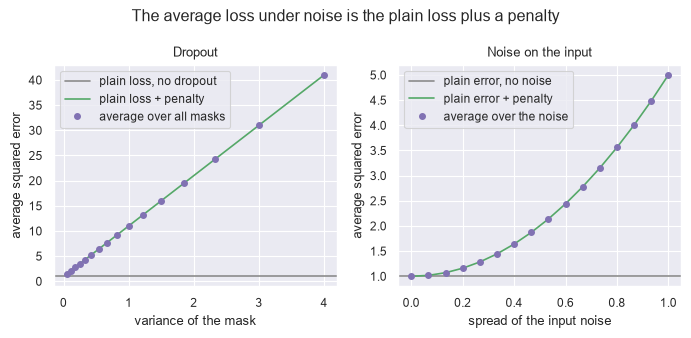

In [9]:
use_style()
keep_probabilities = np.linspace(0.95, 0.2, 16)
variances = np.array([get_mask_variance(keep) for keep in keep_probabilities])
shares, label = np.array([3.0, 1.0]), 5.0
exact_dropout = np.array([get_expected_dropout_loss(*make_mask_table(keep, 2), label, shares) for keep in keep_probabilities])
plain_dropout = (label - shares.sum()) ** 2
formula_dropout = plain_dropout + variances * (shares ** 2).sum()
report("figure 1, left: the exact dropout losses lie on plain + penalty", np.abs(exact_dropout - formula_dropout).max() < 1e-9, f"largest gap {np.abs(exact_dropout - formula_dropout).max():.1e}")
spreads = np.linspace(0, 1, 16)
exact_noise = np.array([get_noisy_error(2.0, 1.0, 3.0, spread * NOISE_SHAPE) for spread in spreads])
plain_noise = (3.0 - 2.0) ** 2
formula_noise = plain_noise + spreads ** 2 * 2.0 ** 2
report("figure 1, right: the exact noisy errors lie on plain + penalty", np.abs(exact_noise - formula_noise).max() < 1e-9, f"largest gap {np.abs(exact_noise - formula_noise).max():.1e}")

figure, (left, right) = plt.subplots(1, 2, figsize=(7, 3.4))
left.axhline(plain_dropout, color=BEFORE, label="plain loss, no dropout")
left.plot(variances, formula_dropout, "-", color=BOUND, label="plain loss + penalty")
left.plot(variances, exact_dropout, "o", color=MODEL, markersize=4, label="average over all masks")
left.set_xlabel("variance of the mask")
left.set_ylabel("average squared error")
left.set_title("Dropout")
left.legend(loc="upper left")
right.axhline(plain_noise, color=BEFORE, label="plain error, no noise")
right.plot(spreads, formula_noise, "-", color=BOUND, label="plain error + penalty")
right.plot(spreads, exact_noise, "o", color=MODEL, markersize=4, label="average over the noise")
right.set_xlabel("spread of the input noise")
right.set_ylabel("average squared error")
right.set_title("Noise on the input")
right.legend(loc="upper left")
figure.suptitle("The average loss under noise is the plain loss plus a penalty")
figure.tight_layout()
save_figure(figure, "21-penalty-on-average")
plt.show()

## Figure 2: a fit with and without dropout

The two fits of Claim 7 on the same 15 points, with the true curve `sin(x)`.

wrote book/figures/21-fit-with-and-without-dropout.png


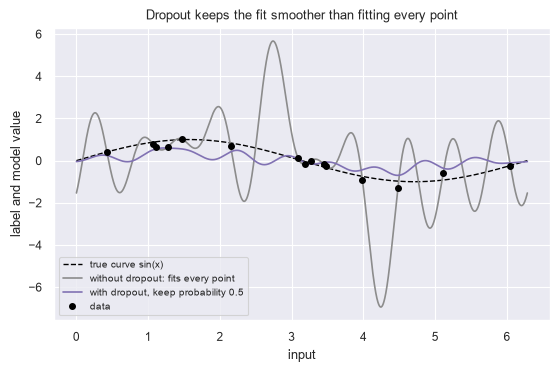

In [10]:
use_style()
figure, axis = plt.subplots(figsize=(6.4, 3.8))
axis.plot(grid, np.sin(grid), "--", color=DATA, linewidth=1, label="true curve sin(x)")
axis.plot(grid, make_features(grid) @ plain_weights, "-", color=BEFORE, label="without dropout: fits every point")
axis.plot(grid, make_features(grid) @ dropout_weights, "-", color=MODEL, label="with dropout, keep probability 0.5")
axis.plot(fit_inputs, fit_labels, "o", color=DATA, markersize=4, label="data")
axis.set_xlabel("input")
axis.set_ylabel("label and model value")
axis.set_title("Dropout keeps the fit smoother than fitting every point")
axis.legend(loc="lower left", fontsize=7)
save_figure(figure, "21-fit-with-and-without-dropout")
plt.show()